# 02 · Baselines — E0 (zero-shot / copy) and E1 (Transformer from scratch)

**Runtime:** GPU (Runtime → Change runtime type → **T4 GPU**).

This notebook establishes the two reference points that every later experiment is compared against:

| ID | Baseline | Question |
|---|---|---|
| E0a | **Copy source** — output the input unchanged | How similar are Kidaw'ida and Swahili on the surface? (both are Bantu languages) |
| E0b | **NLLB-200 zero-shot** with a related-language tag (Kamba, Kikuyu) | Can an existing multilingual MT model translate Kidaw'ida *without* training? → evidence that no system supports it |
| E1 | **Transformer encoder–decoder trained from scratch** on our 15k pairs | What can the data alone achieve, with no pretraining? |

Both directions are evaluated: **swa→dav** (Swahili → Kidaw'ida) and **dav→swa**.

**Metrics:** chrF++ (primary; character n-grams + word bigrams — robust for morphologically rich Bantu words) and BLEU (standard, word n-grams), both via `sacrebleu`, on the cleaned test set (5,058 pairs).

**Saved to Drive** (`MyDrive/kidawida-mt/`):
- `results/experiments.csv` — one row per experiment (shared by all notebooks → the report's experiment table)
- `results/predictions/*.csv` — every test translation with its sentence-level chrF (used for error analysis in notebook 04)
- `models/e1_transformer_<dir>/` — SentencePiece tokenizer + best checkpoint (~30 MB each)
- `figures/e1_training_curves.png`

## 1. Setup: Drive, packages, GPU

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/kidawida-mt'
DATA_DIR    = f'{PROJECT_DIR}/data'
RESULTS_DIR = f'{PROJECT_DIR}/results'
PRED_DIR    = f'{RESULTS_DIR}/predictions'
MODELS_DIR  = f'{PROJECT_DIR}/models'
FIG_DIR     = f'{PROJECT_DIR}/figures'
for d in [RESULTS_DIR, PRED_DIR, MODELS_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

In [ ]:
import sys
import os

# Define log path (fallback to local if Drive is not mounted)
log_dir = PROJECT_DIR if os.path.exists('/content/drive/MyDrive') else '/content'
log_file_path = os.path.join(log_dir, 'execution_log.txt')

class Logger(object):
    def __init__(self, filepath):
        self.terminal = sys.stdout
        self.log = open(filepath, 'a', encoding='utf-8')

    def write(self, message):
        self.terminal.write(message)
        self.log.write(message)
        self.log.flush()  # force write to disk immediately

    def flush(self):
        self.terminal.flush()
        self.log.flush()

# Redirect standard output and error
sys.stdout = Logger(log_file_path)
sys.stderr = sys.stdout

print(f"\n--- Log session started. Writing outputs and errors to: {log_file_path} ---\n")

In [ ]:
# transformers / torch are preinstalled on Colab. We only add the MT metric and tokenizer libraries.
# (Do NOT upgrade huggingface_hub here — that is what caused the version warnings in notebook 01.)
!pip -q install sacrebleu sentencepiece

import math, time, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import sacrebleu
import sentencepiece as spm
import warnings
warnings.filterwarnings('ignore', message='enable_nested_tensor')

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '|', torch.cuda.get_device_name(0) if device == 'cuda' else 'no GPU — switch runtime to T4!')
pd.set_option('display.max_colwidth', 100)

## 2. Load the cleaned splits from notebook 01

In [ ]:
read = lambda name: pd.read_csv(f'{DATA_DIR}/{name}.csv', keep_default_na=False)  # keep words like "NA" as text
train_df, val_df, test_df = read('train'), read('val'), read('test')
print('train', len(train_df), '| val', len(val_df), '| test', len(test_df))

LANG_NAME = {'dav': "Kidaw'ida", 'swa': 'Kiswahili'}
DIRECTIONS = [('swa', 'dav'), ('dav', 'swa')]   # (source, target)

## 3. Shared evaluation helpers

Every experiment (in every notebook) is scored and logged the same way, so results are directly comparable:
- `score()` → corpus BLEU and chrF++ (`word_order=2`).
- `save_predictions()` → source / reference / hypothesis + per-sentence chrF++, for error analysis.
- `log_result()` → appends one row to `results/experiments.csv` (re-running an experiment replaces its old row).

In [ ]:
def score(hyps, refs):
    bleu = sacrebleu.corpus_bleu(hyps, [refs])
    chrf = sacrebleu.corpus_chrf(hyps, [refs], word_order=2)   # chrF++
    return {'BLEU': round(bleu.score, 2), 'chrF++': round(chrf.score, 2)}

def save_predictions(exp_id, src_lang, tgt_lang, srcs, refs, hyps):
    df = pd.DataFrame({'src': srcs, 'ref': refs, 'hyp': hyps})
    df['chrF++'] = [round(sacrebleu.sentence_chrf(h, [r], word_order=2).score, 2) for h, r in zip(hyps, refs)]
    path = f'{PRED_DIR}/{exp_id}_{src_lang}2{tgt_lang}.csv'
    df.to_csv(path, index=False)
    return df

def log_result(exp_id, src_lang, tgt_lang, model, decoding, metrics, notes=''):
    path = f'{RESULTS_DIR}/experiments.csv'
    row = {'exp_id': exp_id, 'direction': f'{src_lang}→{tgt_lang}', 'model': model, 'decoding': decoding,
           **metrics, 'n_test': len(test_df), 'notes': notes, 'timestamp': time.strftime('%Y-%m-%d %H:%M')}
    old = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame()
    if len(old):
        old = old[~((old.exp_id == exp_id) & (old.direction == row['direction']) & (old.decoding == decoding))]
    pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(path, index=False)
    print(f"[{exp_id}] {row['direction']:8} {decoding:10} BLEU={metrics['BLEU']:6.2f}  chrF++={metrics['chrF++']:6.2f}  {notes}")

---
# Part A — E0: does anything work *without* training?

**E0a · Copy baseline.** Kidaw'ida and Swahili are both Bantu languages and share many roots (e.g. *mwana* "child" appears in both), so simply copying the input already earns some character overlap. Any real model must beat this.

**E0b · NLLB-200 zero-shot.** NLLB-200 (NLLB Team et al., 2022) has no Kidaw'ida language code. We ask it to translate into the two closest Kenyan Bantu languages it *does* support — **Kamba (`kam_Latn`)** and **Kikuyu (`kik_Latn`)** — and score the output against the Kidaw'ida reference. For dav→swa we feed Kidaw'ida in, labelled as Swahili or Kamba, and ask for Swahili.
A low score here is quantitative evidence that the strongest open multilingual MT model does not support this language pair.

In [ ]:
for src, tgt in DIRECTIONS:
    srcs, refs = test_df[src].tolist(), test_df[tgt].tolist()
    m = score(srcs, refs)
    save_predictions('E0a_copy', src, tgt, srcs, refs, srcs)
    log_result('E0a_copy', src, tgt, 'copy source', '-', m, 'output = input')

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

NLLB_NAME = 'facebook/nllb-200-distilled-600M'
nllb_tok = AutoTokenizer.from_pretrained(NLLB_NAME)
nllb = AutoModelForSeq2SeqLM.from_pretrained(NLLB_NAME, torch_dtype=torch.float16 if device == 'cuda' else torch.float32).to(device).eval()
print(f'NLLB parameters: {sum(p.numel() for p in nllb.parameters())/1e6:.0f}M')
print('Has a Kidaw\'ida code?', any(code.startswith('dav') for code in nllb_tok.additional_special_tokens))

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

...

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

AttributeError: NllbTokenizer has no attribute additional_special_tokens

In [ ]:
@torch.no_grad()
def nllb_translate(sentences, src_code, tgt_code, batch_size=64, num_beams=4, max_new_tokens=64):
    """Translate with NLLB. Sentences are sorted by length so each batch has little padding, then restored."""
    nllb_tok.src_lang = src_code
    order = np.argsort([len(s) for s in sentences])
    out = [None] * len(sentences)
    bos = nllb_tok.convert_tokens_to_ids(tgt_code)
    for i in range(0, len(order), batch_size):
        idx = order[i:i + batch_size]
        enc = nllb_tok([sentences[j] for j in idx], return_tensors='pt', padding=True,
                       truncation=True, max_length=128).to(device)
        gen = nllb.generate(**enc, forced_bos_token_id=bos, num_beams=num_beams, max_new_tokens=max_new_tokens)
        for j, text in zip(idx, nllb_tok.batch_decode(gen, skip_special_tokens=True)):
            out[j] = text
    return out

# quick look before the full run
print(nllb_translate(test_df.swa[:3].tolist(), 'swh_Latn', 'kam_Latn'))

In [ ]:
E0B_RUNS = [
    # (src, tgt, NLLB source code, NLLB target code)
    ('swa', 'dav', 'swh_Latn', 'kam_Latn'),
    ('swa', 'dav', 'swh_Latn', 'kik_Latn'),
    ('dav', 'swa', 'swh_Latn', 'swh_Latn'),   # Kidaw'ida input labelled as Swahili
    ('dav', 'swa', 'kam_Latn', 'swh_Latn'),   # Kidaw'ida input labelled as Kamba
]
e0b_preds = {}
for src, tgt, sc, tc in E0B_RUNS:
    t0 = time.time()
    srcs, refs = test_df[src].tolist(), test_df[tgt].tolist()
    hyps = nllb_translate(srcs, sc, tc)
    tag = f'E0b_nllb_zeroshot_{sc[:3]}-{tc[:3]}'
    e0b_preds[tag] = save_predictions(tag, src, tgt, srcs, refs, hyps)
    log_result(tag, src, tgt, 'NLLB-200-600M (no training)', 'beam4', score(hyps, refs),
               f'NLLB codes {sc}->{tc}; {time.time()-t0:.0f}s')

In [ ]:
# Qualitative look: what does zero-shot NLLB actually produce?
for tag, df in e0b_preds.items():
    print('\n===', tag)
    display(df.sample(5, random_state=SEED)[['src', 'ref', 'hyp', 'chrF++']])

,src,ref,hyp,chrF++
1962,Mawingu yanapita.,Mawingu ghaweida.,Matu nĩmathengeeaw'a.,15.54
4302,Chai ni mmea muhimu barani Afrika.,Chai ni mmea ghwa mana sana Afrika.,Ĩia nĩ mũtĩ wa vata mũno nthĩ ya Africa.,15.80
2784,Msichana wangu alikuwa hasikii vizuri.,Mwai wapo ndousindee sikira nicha.,Mwĩĩtu wakwa aĩ na thĩna wa kwĩw'a.,9.17
3221,Watumishi wa Mungu wanapitia mengi,Wadumiki wa Mlungu waweidia malazi,Athũkũmi ma Ngai nĩmathĩnaa mũno,6.38
4685,Hapendwi kwa fitina zake,Ndeukundo kwa ndasanya rake,Ndesa kwendwa nũndũ wa maũndũ ala ũkwĩw'a ta ũtekwenda,14.35


,src,ref,hyp,chrF++
1962,Mawingu yanapita.,Mawingu ghaweida.,Mairũ nĩ marathiĩ.,11.81
4302,Chai ni mmea muhimu barani Afrika.,Chai ni mmea ghwa mana sana Afrika.,Chaa nĩ mũtĩ wa bata mũno thĩinĩ wa Afrika.,28.55
2784,Msichana wangu alikuwa hasikii vizuri.,Mwai wapo ndousindee sikira nicha.,Mũirĩtu wakwa ndaiguaga wega.,12.11
3221,Watumishi wa Mungu wanapitia mengi,Wadumiki wa Mlungu waweidia malazi,Athũkũmi a Ngai nĩ macemanagia na maũndũ maingĩ,9.07
4685,Hapendwi kwa fitina zake,Ndeukundo kwa ndasanya rake,Ndaakenagio nĩ mĩtugo yake mĩũru,11.74


,src,ref,hyp,chrF++
1962,Mawingu ghaweida.,Mawingu yanapita.,Mawingu yanatokea.,57.56
4302,Chai ni mmea ghwa mana sana Afrika.,Chai ni mmea muhimu barani Afrika.,Chai ni mmea mkubwa wa mana barani Afrika.,70.28
2784,Mwai wapo ndousindee sikira nicha.,Msichana wangu alikuwa hasikii vizuri.,Na hakika nitawaadhibu.,12.73
3221,Wadumiki wa Mlungu waweidia malazi,Watumishi wa Mungu wanapitia mengi,Watumishi Wazungu Wameandaa Makao,29.95
4685,Ndeukundo kwa ndasanya rake,Hapendwi kwa fitina zake,Utaratibu wa lugha yake,8.60


,src,ref,hyp,chrF++
1962,Mawingu ghaweida.,Mawingu yanapita.,Mawingu yalitokea.,48.03
4302,Chai ni mmea ghwa mana sana Afrika.,Chai ni mmea muhimu barani Afrika.,Chai ni mmea wa kawaida barani Afrika.,68.32
2784,Mwai wapo ndousindee sikira nicha.,Msichana wangu alikuwa hasikii vizuri.,"Hata hivyo, alifanikiwa.",12.61
3221,Wadumiki wa Mlungu waweidia malazi,Watumishi wa Mungu wanapitia mengi,Mchungaji wa Mwezi wa Kwanza akiwa tayari kwa ajili ya maziwa,15.06
4685,Ndeukundo kwa ndasanya rake,Hapendwi kwa fitina zake,Upendo wa kimapenzi,15.47


In [ ]:
# Free GPU memory before training the baseline
del nllb
import gc; gc.collect(); torch.cuda.empty_cache()

---
# Part B — E1: Transformer trained from scratch

### Architecture (Vaswani et al., 2017), sized for a small dataset
```
source ids ─► Embedding(×√d) + sinusoidal positions ─► Encoder ×3 ─► memory
                                                         (self-attention + FFN)
target ids (shifted right, starts with <s>) ─► Embedding + positions ─► Decoder ×3 ─► Linear ─► softmax over vocab
                                         (masked self-attention + cross-attention to memory + FFN)
```
| Hyper-parameter | Value | Why |
|---|---|---|
| Tokenizer | SentencePiece BPE, **joint** vocab of 8,000 trained on train set (both languages) | subwords handle the 17% unseen test words; joint vocab lets shared Bantu roots share pieces |
| d_model / heads / FFN | 256 / 4 / 1024 | small model ≈ 7.5M params: we only have ~70k words per side |
| Layers | 3 encoder + 3 decoder | |
| Dropout | 0.3 | strong regularisation for low-resource data |
| Embeddings | shared between encoder, decoder and output layer (weight tying) | fewer parameters (Press & Wolf, 2017) |
| Loss | cross-entropy with label smoothing 0.1 | |
| Optimiser | AdamW (β = 0.9, 0.98), peak lr 5e-4, 800 warm-up steps, inverse-sqrt decay | standard Transformer schedule |
| Batch / epochs | 64 sentences, up to 60 epochs, early stopping (patience 6) on validation chrF++ | |
| Decoding | greedy (during training) and beam search, beam 4 (final test) | |

One model is trained per direction (swa→dav and dav→swa).

### B1. SentencePiece tokenizer (one per direction folder, same settings)

In [ ]:
VOCAB_SIZE = 8000
PAD, UNK, BOS, EOS = 0, 1, 2, 3
MAX_LEN = 64            # sentences are ≤ 25 words, so 64 subword tokens is plenty

def train_spm(out_dir):
    os.makedirs(out_dir, exist_ok=True)
    corpus = '/content/spm_corpus.txt'
    with open(corpus, 'w') as f:
        for s in pd.concat([train_df.dav, train_df.swa]):
            f.write(s + '\n')
    spm.SentencePieceTrainer.train(
        input=corpus, model_prefix=f'{out_dir}/spm', vocab_size=VOCAB_SIZE, model_type='bpe',
        character_coverage=1.0, pad_id=PAD, unk_id=UNK, bos_id=BOS, eos_id=EOS, seed_sentencepiece_size=1000000)
    return spm.SentencePieceProcessor(model_file=f'{out_dir}/spm.model')

SPM_DIR = f'{MODELS_DIR}/e1_spm'
sp = train_spm(SPM_DIR)

# Tokenisation sanity check: how are words split, and how long are sequences?
for s in [test_df.dav[0], test_df.swa[0]]:
    print(s, '->', sp.encode(s, out_type=str))
for lang in ['dav', 'swa']:
    lens = [len(sp.encode(s)) for s in train_df[lang]]
    print(f'{LANG_NAME[lang]:10} subword tokens/sentence: mean {np.mean(lens):.1f}, max {max(lens)}')
unk_rate = np.mean([t == UNK for s in test_df.dav for t in sp.encode(s)])
print(f'Test <unk> rate (dav): {unk_rate:.4%}')

### B2. Dataset and batching

In [ ]:
from torch.utils.data import Dataset, DataLoader

class PairDataset(Dataset):
    def __init__(self, df, src, tgt):
        self.src = [sp.encode(s)[:MAX_LEN - 1] + [EOS] for s in df[src]]
        self.tgt = [[BOS] + sp.encode(s)[:MAX_LEN - 2] + [EOS] for s in df[tgt]]
    def __len__(self): return len(self.src)
    def __getitem__(self, i): return self.src[i], self.tgt[i]

def pad_batch(seqs):
    L = max(len(s) for s in seqs)
    return torch.tensor([s + [PAD] * (L - len(s)) for s in seqs])

def collate(batch):
    src, tgt = zip(*batch)
    return pad_batch(src), pad_batch(tgt)

def make_loader(df, src, tgt, shuffle, bs=64):
    return DataLoader(PairDataset(df, src, tgt), batch_size=bs, shuffle=shuffle, collate_fn=collate)

### B3. Model

In [ ]:
class PositionalEncoding(nn.Module):
    """Fixed sinusoidal position signal added to embeddings (Vaswani et al., 2017)."""
    def __init__(self, d_model, dropout, max_len=512):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
        self.register_buffer('pe', pe.unsqueeze(0))
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):                       # x: (batch, seq, d_model)
        return self.dropout(x + self.pe[:, :x.size(1)])

class Seq2SeqTransformer(nn.Module):
    def __init__(self, vocab_size, d_model=256, nhead=4, n_enc=3, n_dec=3, d_ff=1024, dropout=0.3):
        super().__init__()
        self.d_model = d_model
        self.embed = nn.Embedding(vocab_size, d_model, padding_idx=PAD)   # shared src/tgt embeddings
        self.pos = PositionalEncoding(d_model, dropout)
        self.transformer = nn.Transformer(d_model, nhead, n_enc, n_dec, d_ff, dropout,
                                          batch_first=True, norm_first=True)  # pre-LayerNorm: more stable
        self.out = nn.Linear(d_model, vocab_size)
        self.out.weight = self.embed.weight                                   # weight tying
        # Small init: tied output layer needs logits of sensible size (std = d^-0.5, so embed*sqrt(d) ≈ unit scale)
        nn.init.normal_(self.embed.weight, mean=0.0, std=d_model ** -0.5)
        with torch.no_grad():
            self.embed.weight[PAD].zero_()

    def encode(self, src):
        src_pad = src == PAD                                                  # True = ignore this position
        x = self.pos(self.embed(src) * math.sqrt(self.d_model))
        return self.transformer.encoder(x, src_key_padding_mask=src_pad), src_pad

    def decode(self, tgt, memory, src_pad):
        T = tgt.size(1)
        causal = torch.triu(torch.ones(T, T, dtype=torch.bool, device=tgt.device), diagonal=1)  # no peeking ahead
        y = self.pos(self.embed(tgt) * math.sqrt(self.d_model))
        h = self.transformer.decoder(y, memory, tgt_mask=causal, tgt_key_padding_mask=(tgt == PAD),
                                     memory_key_padding_mask=src_pad)
        return self.out(h)                                                    # (batch, T, vocab) logits

    def forward(self, src, tgt_in):
        memory, src_pad = self.encode(src)
        return self.decode(tgt_in, memory, src_pad)

_m = Seq2SeqTransformer(VOCAB_SIZE)
print(f'Parameters: {sum(p.numel() for p in _m.parameters())/1e6:.2f}M'); del _m

### B4. Decoding
- **Greedy:** at each step take the single most likely token. Fast; used on the validation set during training.
- **Beam search (k = 4):** keep the 4 best partial translations at each step; finished hypotheses are ranked by log-probability divided by length^0.6 (so short outputs aren't unfairly favoured). Used for the final test score — the same beam size as NLLB, for a fair comparison.

In [ ]:
@torch.no_grad()
def greedy_decode(model, src, max_len=MAX_LEN):
    memory, src_pad = model.encode(src)
    ys = torch.full((src.size(0), 1), BOS, device=src.device)
    done = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    for _ in range(max_len):
        nxt = model.decode(ys, memory, src_pad)[:, -1].argmax(-1)
        nxt = torch.where(done, torch.full_like(nxt, PAD), nxt)
        ys = torch.cat([ys, nxt.unsqueeze(1)], dim=1)
        done |= nxt == EOS
        if done.all():
            break
    return ys[:, 1:].tolist()

@torch.no_grad()
def beam_decode(model, src_ids, beam=4, max_len=MAX_LEN, alpha=0.6):
    src = torch.tensor([src_ids], device=device)
    memory, src_pad = model.encode(src)
    beams, finished = [([BOS], 0.0)], []
    for _ in range(max_len):
        seqs = torch.tensor([b[0] for b in beams], device=device)
        logp = F.log_softmax(model.decode(seqs, memory.expand(len(beams), -1, -1),
                                          src_pad.expand(len(beams), -1))[:, -1].float(), dim=-1)
        top_v, top_i = logp.topk(beam, dim=-1)
        cands = [(seq + [i], s + v) for (seq, s), vs, is_ in zip(beams, top_v.tolist(), top_i.tolist())
                 for v, i in zip(vs, is_)]
        cands.sort(key=lambda c: -c[1])
        beams = []
        for seq, s in cands:
            if seq[-1] == EOS:
                finished.append((seq, s / (len(seq) - 1) ** alpha))
            else:
                beams.append((seq, s))
            if len(beams) == beam:
                break
        if len(finished) >= beam or not beams:
            break
    if not finished:
        finished = [(seq, s / (len(seq) - 1) ** alpha) for seq, s in beams]
    return max(finished, key=lambda c: c[1])[0][1:]

def ids_to_text(ids):
    ids = ids[:ids.index(EOS)] if EOS in ids else ids
    return sp.decode([i for i in ids if i not in (PAD, BOS)])

def translate_df(model, df, src, mode='greedy', bs=128):
    model.eval()
    if mode == 'greedy':
        out = []
        for s, _ in make_loader(df, src, src, shuffle=False, bs=bs):
            out += [ids_to_text(x) for x in greedy_decode(model, s.to(device))]
        return out
    return [ids_to_text(beam_decode(model, sp.encode(s)[:MAX_LEN - 1] + [EOS])) for s in df[src]]

### B5. Training loop

In [ ]:
def train_model(src, tgt, epochs=60, lr=5e-4, warmup=800, patience=6, label_smoothing=0.1):
    set_seed()
    out_dir = f'{MODELS_DIR}/e1_transformer_{src}2{tgt}'
    os.makedirs(out_dir, exist_ok=True)
    train_dl = make_loader(train_df, src, tgt, shuffle=True)
    val_dl = make_loader(val_df, src, tgt, shuffle=False, bs=128)

    model = Seq2SeqTransformer(VOCAB_SIZE).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.98), eps=1e-9, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.LambdaLR(            # linear warm-up, then inverse-sqrt decay
        opt, lambda step: min((step + 1) / warmup, math.sqrt(warmup / (step + 1))))
    loss_fn = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=label_smoothing)
    scaler = torch.amp.GradScaler(enabled=(device == 'cuda'))

    history, best, bad = [], -1.0, 0
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); tot = n = 0
        for s, t in train_dl:
            s, t = s.to(device), t.to(device)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(device == 'cuda')):
                logits = model(s, t[:, :-1])                  # teacher forcing: predict t[1:] from t[:-1]
                loss = loss_fn(logits.reshape(-1, logits.size(-1)), t[:, 1:].reshape(-1))
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * s.size(0); n += s.size(0)

        model.eval(); vtot = vn = 0
        with torch.no_grad():
            for s, t in val_dl:
                s, t = s.to(device), t.to(device)
                logits = model(s, t[:, :-1])
                vtot += loss_fn(logits.reshape(-1, logits.size(-1)), t[:, 1:].reshape(-1)).item() * s.size(0); vn += s.size(0)
        val_chrf = score(translate_df(model, val_df, src), val_df[tgt].tolist())['chrF++']
        history.append({'epoch': ep, 'train_loss': tot / n, 'val_loss': vtot / vn, 'val_chrF++': val_chrf})
        print(f'ep {ep:2d} | train {tot/n:.3f} | val {vtot/vn:.3f} | val chrF++ {val_chrf:5.2f} | {time.time()-t0:.0f}s')

        if val_chrf > best:
            best, bad = val_chrf, 0
            torch.save(model.state_dict(), f'{out_dir}/best.pt')   # ~30 MB, saved straight to Drive
        else:
            bad += 1
            if bad >= patience:
                print(f'Early stopping: no val improvement for {patience} epochs (best chrF++ {best:.2f})')
                break

    pd.DataFrame(history).to_csv(f'{out_dir}/history.csv', index=False)
    model.load_state_dict(torch.load(f'{out_dir}/best.pt', map_location=device))
    return model, pd.DataFrame(history)

### B6. Train both directions (~10–20 min total on a T4)

In [ ]:
e1_models, e1_hist = {}, {}
for src, tgt in DIRECTIONS:
    print(f'\n===== E1 {LANG_NAME[src]} → {LANG_NAME[tgt]} =====')
    e1_models[(src, tgt)], e1_hist[(src, tgt)] = train_model(src, tgt)

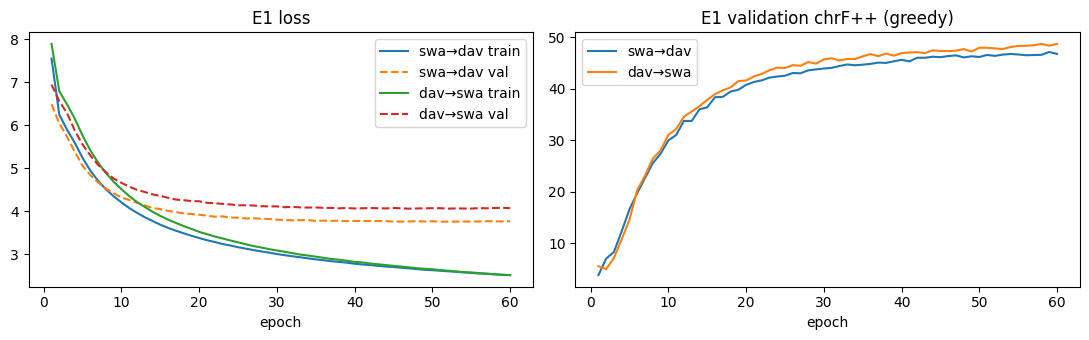

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for (src, tgt), h in e1_hist.items():
    lbl = f'{src}→{tgt}'
    axes[0].plot(h.epoch, h.train_loss, label=f'{lbl} train'); axes[0].plot(h.epoch, h.val_loss, '--', label=f'{lbl} val')
    axes[1].plot(h.epoch, h['val_chrF++'], label=lbl)
axes[0].set_title('E1 loss'); axes[0].set_xlabel('epoch'); axes[0].legend()
axes[1].set_title('E1 validation chrF++ (greedy)'); axes[1].set_xlabel('epoch'); axes[1].legend()
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/e1_training_curves.png', dpi=150); plt.show()

### B7. Test-set evaluation (greedy and beam 4)

In [ ]:
e1_preds = {}
for (src, tgt), model in e1_models.items():
    srcs, refs = test_df[src].tolist(), test_df[tgt].tolist()
    for mode in ['greedy', 'beam4']:
        t0 = time.time()
        hyps = translate_df(model, test_df, src, mode='greedy' if mode == 'greedy' else 'beam')
        e1_preds[(src, tgt, mode)] = save_predictions(f'E1_transformer_{mode}', src, tgt, srcs, refs, hyps)
        log_result('E1_transformer', src, tgt, 'Transformer from scratch (7.5M)', mode, score(hyps, refs),
                   f'best epoch {int(e1_hist[(src, tgt)]["val_chrF++"].idxmax()) + 1}; {time.time()-t0:.0f}s decode')

In [ ]:
# Best and worst E1 translations (beam) — a first look for error analysis
for src, tgt in DIRECTIONS:
    df = e1_preds[(src, tgt, 'beam4')]
    print(f'\n=== {src}→{tgt}: best ===');  display(df.sort_values('chrF++', ascending=False).head(5))
    print(f'=== {src}→{tgt}: worst ==='); display(df.sort_values('chrF++').head(5))

,src,ref,hyp,chrF++
4983,Nimeshiba,Naghuda,Naghuda,100.0
2190,Mama ameamka salama?,Mao waw'uka mana?,Mao waw'uka mana?,100.0
4251,Akapanda mlimani,Ukajoka mghondinyi,Ukajoka mghondinyi,100.0
632,Viatu vyake vimeraruka,Vadu vake verashuka,Vadu vake verashuka,100.0
4287,Ndege wanaweza kuruka juu.,Nyonyi radima kurama ighu.,Nyonyi radima kurama ighu.,100.0


,src,ref,hyp,chrF++
4487,huku,nokunu,ichia,0.00
3974,Tegemeo,Isuwirio,Seme,0.00
4760,Tuambie,Dije malagho putu,Dezere,2.16
521,changamoto,changamodo,wasi,2.27
4587,imee,Ndeimuse,lwae,2.78


,src,ref,hyp,chrF++
4983,Naghuda,Nimeshiba,Nimeshiba,100.0
75,Mbuw'a yaw'o yechua magho mabaha.,Shamba lao limejaa mawe makubwa,Shamba lao limejaa mawe makubwa,100.0
5007,Midi idima kukaia na mbashu ndazi.,Miti inaweza kuwa na matawi mengi.,Miti inaweza kuwa na matawi mengi.,100.0
2413,Mshushure,Manyunyu,Manyunyu,100.0
5010,Poilwa ituku jako!,Furahia siku yako!,Furahia siku yako!,100.0


,src,ref,hyp,chrF++
915,iyao,gani,shule,0.00
3464,Naighu,juu,nalale,0.00
4301,Vichuku,ukoo,Vijamii,0.00
3974,Isuwirio,Tegemeo,Uvumilivu ni vikuu,1.62
1117,Nyeche,Kombamwiko,Nije,2.27


## Results so far

In [ ]:
res = pd.read_csv(f'{RESULTS_DIR}/experiments.csv')
res[['exp_id', 'direction', 'model', 'decoding', 'BLEU', 'chrF++', 'notes']]

,exp_id,direction,model,decoding,BLEU,chrF++,notes
0,E0a_copy,swa→dav,copy source,-,1.73,18.95,output = input
1,E0a_copy,dav→swa,copy source,-,1.73,19.26,output = input
2,E0b_nllb_zeroshot_swh-kam,swa→dav,NLLB-200-600M (no training),beam4,0.18,10.64,NLLB codes swh_Latn->kam_Latn; 152s
3,E0b_nllb_zeroshot_swh-kik,swa→dav,NLLB-200-600M (no training),beam4,0.21,10.72,NLLB codes swh_Latn->kik_Latn; 149s
4,E0b_nllb_zeroshot_swh-swh,dav→swa,NLLB-200-600M (no training),beam4,2.81,20.67,NLLB codes swh_Latn->swh_Latn; 138s
5,E0b_nllb_zeroshot_kam-swh,dav→swa,NLLB-200-600M (no training),beam4,1.97,17.71,NLLB codes kam_Latn->swh_Latn; 130s
6,E1_transformer,swa→dav,Transformer from scratch (7.5M),greedy,17.39,46.31,best epoch 59; 18s decode
7,E1_transformer,swa→dav,Transformer from scratch (7.5M),beam4,18.07,46.85,best epoch 59; 233s decode
8,E1_transformer,dav→swa,Transformer from scratch (7.5M),greedy,21.55,48.69,best epoch 60; 14s decode
9,E1_transformer,dav→swa,Transformer from scratch (7.5M),beam4,22.08,49.06,best epoch 60; 190s decode
